In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit

In [28]:
data = sm.datasets.sunspots.load_pandas().data
y = data["SUNACTIVITY"].values

# Add lagged features
def add_lagged_features(data, lag=12):
    X, y = [], []

    for i in range(lag, len(data)):
        X.append(data[i-lag:i])
        y.append(data[i])

    return np.array(X), np.array(y)

X, y = add_lagged_features(y, lag=12)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Scale inputs
x_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Scale targets
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
)

In [29]:
import torch
import torch.nn as nn

torch.manual_seed(42)

class MLP(nn.Module):
    def __init__(self, input_size=12):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 50),
            nn.Tanh(),

            nn.Linear(50, 25),
            nn.Tanh(),

            nn.Linear(25, 1)
        )

    def forward(self, x):
        return self.network(x)

model = MLP(input_size=X_train.shape[1])

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=50, bias=True)
    (1): Tanh()
    (2): Linear(in_features=50, out_features=25, bias=True)
    (3): Tanh()
    (4): Linear(in_features=25, out_features=1, bias=True)
  )
)


In [30]:
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_scaled, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

# Combine inputs and targets
train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

In [31]:
# Mean Squared Error loss
criterion = nn.MSELoss()

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [32]:
# Training
epochs = 1000
loss_history = []

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:

        # 1. Forward propagation
        predictions = model(X_batch)

        # 2. Calculate loss
        loss = criterion(predictions, y_batch)

        # 3. Reset gradients
        optimizer.zero_grad()

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        optimizer.step()

        total_loss += loss.item() * len(X_batch)

    avg_loss = total_loss / len(train_dataset)
    loss_history.append(avg_loss)


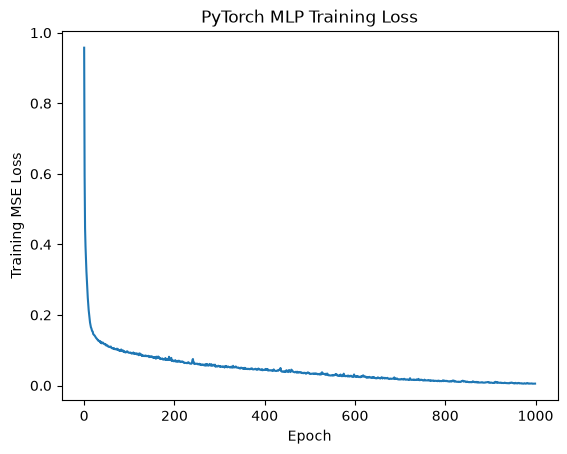

In [33]:
import matplotlib.pyplot as plt

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("PyTorch MLP Training Loss")
plt.show()

In [34]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Switch to evaluation mode
model.eval()

# Disable gradient calculations
with torch.no_grad():
    y_pred_scaled = model(X_test_tensor).numpy()

# Convert predictions back to original scale
y_pred = y_scaler.inverse_transform(
    y_pred_scaled
).ravel()

# Calculate RMSE and MAE
rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

mae = mean_absolute_error(y_test, y_pred)

print(f"PyTorch MLP RMSE: {rmse:.4f}")
print(f"PyTorch MLP MAE: {mae:.4f}")



PyTorch MLP RMSE: 25.8364
PyTorch MLP MAE: 20.1110


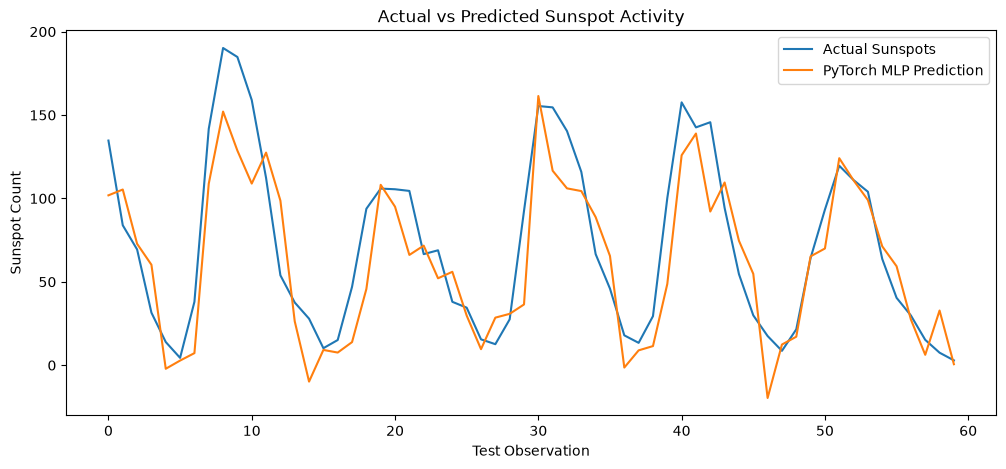

In [35]:
plt.figure(figsize=(12, 5))

plt.plot(y_test, label="Actual Sunspots")
plt.plot(y_pred, label="PyTorch MLP Prediction")

plt.xlabel("Test Observation")
plt.ylabel("Sunspot Count")
plt.title("Actual vs Predicted Sunspot Activity")

plt.legend()
plt.show()